# Assignment 8: NLP-I: Text Preprocessing

**UCS420 : Cognitive Computing**  
**Name:** Harshpreet Singh  
**Roll Number:** 1024170162  
**Branch:** Computer Science and Engineering

In [16]:
%pip install nltk pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [17]:
ROLL_NO = 1024170162         
NAME = "Harshpreet Singh"          

import nltk
import re
import string
import math
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [18]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [19]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [20]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170162   Name: Harshpreet Singh   Fingerprint: C916117A   Tickets: 14

Ticket_ID                                                                               Ticket_Text
      T01                                 The laptop stopped responding. Is there another solution?
      T02                               The printer is showing an error. Is there another solution?
      T03                                               The state-of-the-art lab (Lab-3) is closed.
      T04                                               The email is showing an error. Please help.
      T05            I am unable to use the projector when I use mobile hotspot. Please resolve it.
      T06                               Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T07          I am unable to use the Python when connected to campus Wi-Fi. Please resolve it.
      T08                                                     The Wi-Fi works, but the VPN doesn't.
      T09   

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [21]:
rows = []
all_processed = []
for _, ticket in df.iterrows():
    result = process_ticket(ticket["Ticket_Text"])
    all_processed.append(result)
    rows.append({
        "Ticket ID": ticket["Ticket_ID"],
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)
total = {"Ticket ID": "TOTAL"}
for column in summary.columns[1:]:
    total[column] = summary[column].sum()
summary = pd.concat([summary, pd.DataFrame([total])], ignore_index=True)
display(summary)

selected_id = df.iloc[0]["Ticket_ID"]
selected = all_processed[0]
print("Selected ticket:", selected_id)
for key in ["tokens", "punct", "stops", "final"]:
    print(f"{key}: {selected[key]}")

fragments = sorted({t for p in all_processed for t in p["final"] if t in {"ca", "wo", "n't", "'s", "'m", "'re", "'ve", "'ll"}})
print("\nContraction fragments in the final tokens:", fragments if fragments else "None in this dataset")

,Ticket ID,Sentences,Tokens,Punctuation,Stopwords,Unique Tokens,Final Tokens
0,T01,2,10,2,3,10,5
1,T02,2,12,2,5,11,5
2,T03,1,9,3,2,9,4
3,T04,2,10,2,3,9,5
4,T05,2,17,2,7,14,8
5,T06,1,9,2,2,9,5
6,T07,2,17,2,7,15,8
7,T08,1,10,2,4,9,4
8,T09,2,15,2,6,15,7
9,T10,2,11,2,4,11,5


Selected ticket: T01
tokens: ['the', 'laptop', 'stopped', 'responding', '.', 'is', 'there', 'another', 'solution', '?']
punct: ['.', '?']
stops: ['the', 'is', 'there']
final: ['laptop', 'stopped', 'responding', 'another', 'solution']

Contraction fragments in the final tokens: ["n't"]


**Observation:** Tokens such as ca, n't, or 's may appear when NLTK splits contractions like can't and isn't. They are grammatical fragments rather than standalone words. The final line of Q1 identifies which of these fragments actually occur in my generated dataset.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [22]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
raw_tickets = df["Ticket_Text"].tolist()

def extract_items(text):
    return {
        "Long words": re.findall(r"(?<![A-Za-z])[A-Za-z]{6,}(?![A-Za-z])", text),
        "Numbers": re.findall(r"(?<!\w)\d+(?:,\d{3})*(?:\.\d+)*(?!\w)", text),
        "Capitalized": re.findall(r"\b[A-Z][a-z]+\b", text),
        "Vowel words": re.findall(r"\b[AEIOUaeiou][A-Za-z]*\b", text)
    }

for label, texts in [("GENERATED TICKETS", raw_tickets), ("TEST LINES", TEST_LINES)]:
    print("\n", label)
    for i, line in enumerate(texts, 1):
        print(f"\n{i}. {line}")
        for key, values in extract_items(line).items():
            print(key, ":", values)


 GENERATED TICKETS

1. The laptop stopped responding. Is there another solution?
Long words : ['laptop', 'stopped', 'responding', 'another', 'solution']
Numbers : []
Capitalized : ['The', 'Is']
Vowel words : ['Is', 'another']

2. The printer is showing an error. Is there another solution?
Long words : ['printer', 'showing', 'another', 'solution']
Numbers : []
Capitalized : ['The', 'Is']
Vowel words : ['is', 'an', 'error', 'Is', 'another']

3. The state-of-the-art lab (Lab-3) is closed.
Long words : ['closed']
Numbers : ['3']
Capitalized : ['The', 'Lab']
Vowel words : ['of', 'art', 'is']

4. The email is showing an error. Please help.
Long words : ['showing', 'Please']
Numbers : []
Capitalized : ['The', 'Please']
Vowel words : ['email', 'is', 'an', 'error']

5. I am unable to use the projector when I use mobile hotspot. Please resolve it.
Long words : ['unable', 'projector', 'mobile', 'hotspot', 'Please', 'resolve']
Numbers : []
Capitalized : ['Please']
Vowel words : ['I', 'am', 'unabl

In [23]:
email_pattern = r"(?<!\w)[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}"
url_pattern = r"(?:https?://|www\.)[^\s,;]+"
phone_pattern = r"(?<!\w)(?:\+91[ -]?)?\d{5}[ -]\d{5}(?!\w)|(?<!\w)\d{3,4}-\d{3,4}-\d{3,4}(?!\w)"

def hide_details(text):
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(url_pattern, "<URL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    return text

for label, texts in [("TEST LINES", TEST_LINES), ("GENERATED TICKETS", raw_tickets)]:
    print("\n", label)
    for line in texts:
        print("Before:", line)
        print("After: ", hide_details(line))
        print()

from nltk.tokenize import sent_tokenize
sentence_starts = []
for ticket in raw_tickets:
    for sentence in sent_tokenize(ticket):
        match = re.match(r"\s*([A-Z][a-z]+)\b", sentence)
        if match:
            sentence_starts.append(match.group(1))
print("Capitalized first words of sentences:", sentence_starts)
print("Number of occurrences:", len(sentence_starts))


 TEST LINES
Before: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
After:  Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>

Before: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
After:  Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.

Before: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
After:  The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.


 GENERATED TICKETS
Before: The laptop stopped responding. Is there another solution?
After:  The laptop stopped responding. Is there another solution?

Before: The printer is showing an error. Is there another solution?
After:  The printer is showing an error. Is there another solution?

Before: The state-of-the-art lab (Lab-3) is closed.
After:  The state-of-the-art lab (Lab-3) is closed.

Before: The email is showing an error. Please help.
After:  The email

**Observation:** The output above counts capitalized first words that match the simple [A-Z][a-z]+ pattern. These are sentence-start capitalization occurrences, not necessarily proper nouns. Acronyms (such as LMS) are excluded by this particular pattern. This avoids claiming every capitalized word is a name.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [24]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

pattern = (
    r"(?:https?://|www\.)[^\s,;]+|"                  
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"  
    r"(?:\+91[ -]?)?\d{5}[ -]\d{5}|\d{3,4}-\d{3,4}-\d{3,4}|"  
    r"\d+(?:\.\d+)+|"                            
    r"[A-Za-z]+(?:[-'][A-Za-z]+)*|"                     
    r"\d+|[^\w\s]"                                
)
tokenizer = RegexpTokenizer(pattern)

def my_tokenize(text):
    return tokenizer.tokenize(text)

for label, texts in [("TEST LINES", TEST_LINES), ("GENERATED TICKETS", raw_tickets)]:
    print("\n", label)
    for line in texts:
        print("\nText:", line)
        print("Custom:", my_tokenize(line))
        print("NLTK:  ", word_tokenize(line))


 TEST LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
NLTK:   ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK:   ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Custom: ['The', '

In [25]:
different_ids = []
for _, ticket in df.iterrows():
    if my_tokenize(ticket["Ticket_Text"]) != word_tokenize(ticket["Ticket_Text"]):
        different_ids.append(ticket["Ticket_ID"])
print("Tickets tokenized differently:", len(different_ids), "out of", len(df))
print("Ticket IDs:", different_ids)

examples = ["isn't", "state-of-the-art", "Version 2.0.1", "helpdesk@university.edu"]
for example in examples:
    print(f"{example}: custom={my_tokenize(example)} | NLTK={word_tokenize(example)}")

Tickets tokenized differently: 5 out of 14
Ticket IDs: ['T03', 'T06', 'T08', 'T11', 'T14']
isn't: custom=["isn't"] | NLTK=['is', "n't"]
state-of-the-art: custom=['state-of-the-art'] | NLTK=['state-of-the-art']
Version 2.0.1: custom=['Version', '2.0.1'] | NLTK=['Version', '2.0.1']
helpdesk@university.edu: custom=['helpdesk@university.edu'] | NLTK=['helpdesk', '@', 'university.edu']


**Observation:** Q3 prints the exact number of differently tokenized tickets for roll number 1024170162. Three differences to look for are contractions (isn't), hyphenated words (state-of-the-art), and email addresses. The custom tokenizer keeps these together when its pattern matches; NLTK's default tokenizer may split them into smaller pieces.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [26]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer

final_words = [word for processed in all_processed for word in processed["final"]]
unique_words = sorted(set(final_words))
porter = PorterStemmer()
lancaster = LancasterStemmer()

ing_words = [w for w in unique_words if w.endswith("ing") and len(w) > 4]
print("Dataset words ending with 'ing':", ing_words)
regexp_stemmer = RegexpStemmer(r"ing$")
lemmatizer = WordNetLemmatizer()

def wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    if tag.startswith("V"):
        return "v"
    if tag.startswith("R"):
        return "r"
    return "n"

rows = []
for word, tag in nltk.pos_tag(unique_words):
    outputs = [porter.stem(word), lancaster.stem(word),
               regexp_stemmer.stem(word), lemmatizer.lemmatize(word, wordnet_pos(tag))]
    if len(set(outputs)) > 1:
        rows.append({"Word": word, "Porter": outputs[0], "Lancaster": outputs[1],
                     "Regexp": outputs[2], "POS Lemma": outputs[3]})

stem_table = pd.DataFrame(rows)
display(stem_table)
print("Regex rule: remove 'ing' only from the end of a token.")
print("Two supporting dataset examples:", ing_words[:2] if len(ing_words) >= 2 else ing_words)

print("\nPotential over-stemming (non-dictionary-looking reduction):")
display(stem_table[stem_table["Lancaster"].str.len() < stem_table["POS Lemma"].str.len()].head(5))
print("Potential under-stemming (Regexp leaves an inflection unchanged):")
display(stem_table[(stem_table["Regexp"] == stem_table["Word"]) &
                   (stem_table["POS Lemma"] != stem_table["Word"])].head(5))

Dataset words ending with 'ing': ['asking', 'responding', 'showing', 'uploading', 'working']


,Word,Porter,Lancaster,Regexp,POS Lemma
0,another,anoth,anoth,another,another
1,campus,campu,camp,campus,campus
2,closed,close,clos,closed,close
3,computer,comput,comput,computer,computer
4,connected,connect,connect,connected,connect
5,error,error,er,error,error
6,failed,fail,fail,failed,fail
7,file,file,fil,file,file
8,keeps,keep,keep,keeps,keep
9,latest,latest,latest,latest,late


Regex rule: remove 'ing' only from the end of a token.
Two supporting dataset examples: ['asking', 'responding']

Potential over-stemming (non-dictionary-looking reduction):


,Word,Porter,Lancaster,Regexp,POS Lemma
0,another,anoth,anoth,another,another
1,campus,campu,camp,campus,campus
2,closed,close,clos,closed,close
3,computer,comput,comput,computer,computer
5,error,error,er,error,error


Potential under-stemming (Regexp leaves an inflection unchanged):


,Word,Porter,Lancaster,Regexp,POS Lemma
2,closed,close,clos,closed,close
4,connected,connect,connect,connected,connect
6,failed,fail,fail,failed,fail
8,keeps,keep,keep,keeps,keep
9,latest,latest,latest,latest,late


**Observation:** Over-stemming removes too much of a word (Lancaster sometimes produces a shortened fragment); under-stemming leaves an inflected word unchanged (our ing$ regex does not handle endings like -ed or -s). The two short tables in Q4 display actual candidates from the generated tickets, rather than invented examples.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

In [27]:
S1 = [w for result in all_processed for w in result["tokens"]]
S2 = [w for result in all_processed for w in result["tokens"] if not is_punct(w)]
S3 = [w for result in all_processed for w in result["final"]]
S4 = [porter.stem(w) for w in S3]

def corpus_stats(words):
    return {"Total tokens": len(words),
            "Unique tokens": len(set(words)),
            "TTR": round(len(set(words)) / len(words), 3) if words else 0}

stats = pd.DataFrame({name: corpus_stats(words) for name, words in
                      [("S1: All", S1), ("S2: No punctuation", S2),
                       ("S3: Final", S3), ("S4: Porter", S4)]}).T
display(stats)
print("TTR difference, S4 - S1:", round(stats.loc["S4: Porter", "TTR"] - stats.loc["S1: All", "TTR"], 3))

,Total tokens,Unique tokens,TTR
S1: All,180.0,89.0,0.494
S2: No punctuation,152.0,82.0,0.539
S3: Final,87.0,61.0,0.701
S4: Porter,87.0,59.0,0.678


TTR difference, S4 - S1: 0.184


In [28]:
print("Top 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

Top 10 words in S1:
[('.', 19), ('the', 15), ('i', 9), ('is', 7), ('to', 7), ('use', 5), ('another', 4), ('there', 3), ('solution', 3), ('?', 3)]

Top 10 words in S3:
[('use', 5), ('another', 4), ('solution', 3), ('please', 3), ('unable', 3), ('laptop', 2), ('printer', 2), ('showing', 2), ('error', 2), ('mobile', 2)]


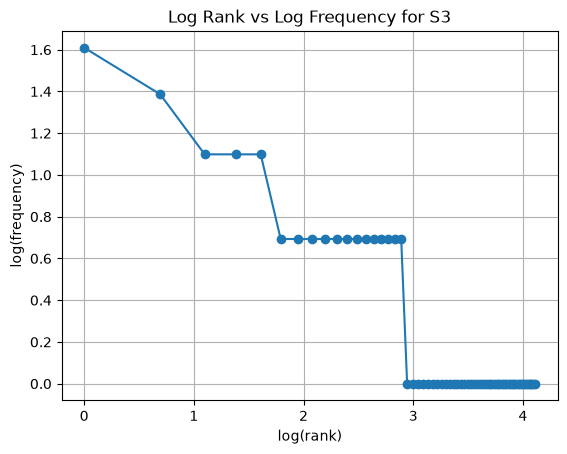

In [29]:
frequency_list = Counter(S3).most_common()

ranks = []
frequencies = []

for rank, item in enumerate(frequency_list, start=1):
    word = item[0]
    count = item[1]

    ranks.append(math.log(rank))
    frequencies.append(math.log(count))

plt.plot(ranks, frequencies, marker="o")
plt.xlabel("log(rank)")
plt.ylabel("log(frequency)")
plt.title("Log Rank vs Log Frequency for S3")
plt.grid(True)
plt.show()

In [30]:
def top_bigrams(use_final=False):
    pairs = []
    for result in all_processed:
        words = result["final"] if use_final else result["tokens"]
        pairs.extend(list(zip(words[:-1], words[1:])))
    return Counter(pairs).most_common(5)

print("S1 top 5 bigrams:", top_bigrams())
print("S3 top 5 bigrams:", top_bigrams(use_final=True))

S1 top 5 bigrams: [(('.', 'is'), 3), (('is', 'there'), 3), (('there', 'another'), 3), (('another', 'solution'), 3), (('solution', '?'), 3)]
S3 top 5 bigrams: [(('another', 'solution'), 3), (('unable', 'use'), 3), (('showing', 'error'), 2), (('use', 'mobile'), 2), (('mobile', 'hotspot'), 2)]


**Observation:** Type–token ratio (TTR) = unique tokens / total tokens. From S1 to S2, punctuation is removed; from S2 to S3, stopwords are removed; and from S3 to S4, Porter stemming merges some different word forms. These operations change both the numerator and denominator, so TTR need not decrease at every step. The table above shows the actual change for my tickets.

## Q6. Interpretation (short answers)

**(a) Why does TTR change from S1 to S4?** Removing punctuation and stopwords changes the number of tokens. Stemming also combines related word forms, changing the number of distinct tokens. The exact TTR values are printed in Q5.

**(b) One difference between the two tokenizers:** My tokenizer treats isn't as a single token, while word_tokenize() usually splits it into is and n't. The comparison in Q3 also tests examples from my generated dataset.

**(c) One undesirable stemming result:** Lancaster can remove excessive characters and return a word fragment that is harder to understand. The Q4 table gives examples drawn from my tickets.

**(d) Why POS-aware lemmatization can be better:** A word tagged as a verb can be reduced to its dictionary verb form, while stemming follows suffix rules without grammatical context. For example, running may be lemmatized to run as a verb. The Q4 table shows the word forms present in my dataset.